# 1. modell – Embedding + GlobalAveragePooling1D + Dense (baseline)

**Architektúra:** `Embedding → GlobalAveragePooling1D → Dense(64, relu) → Dropout → Dense(1, sigmoid)`

Az adat-előkészítés, a felosztás, a tokenizer és a kiértékelés a közös `dl_prep.py`-ból jön, ugyanúgy, mint a többi DL modellnél:
- cikkenkénti GroupShuffleSplit (random_state=42), a test **csak a legvégén** kerül elő,
- a train-ből 12% (cikkenként) a validációs halmaz, erre figyel az EarlyStopping,
- egy tokenizer, csak a train szövegeken illesztve, `num_words=20 000`, `maxlen` = 95. percentilis.

**Kísérletek** (mindegyik a *validációs* halmazon, 3 seed átlaga, mert egy-egy futás szórása 2–3 százalékpont):
1. `mask_zero=True` vagy `False`: maszk nélkül a GlobalAveragePooling a padding-nullák embeddingjét is beleátlagolja.
2. Dropout-arány: 0 / 0,2 / 0,3 / 0,5, valamint egy extra Dropout a pooling után.
3. Tanulási görbe Dropout nélkül és Dropouttal, EarlyStopping nélkül 30 epochon: itt látszik, hol kezd emelkedni a val_loss.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

import dl_prep as dp

SEEDS = [42, 43, 44]
data = dp.load_data()
print(data.summary())

I0000 00:00:1794300338.137213   10214 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794300338.137683   10214 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794300338.178966   10214 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794300339.192284   10214 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794300339.192603   10214 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


train: 10370 mondat (527 cikk) | val: 1446 (72 cikk) | test: 3048 (150 cikk)
szókincs (train): 11893 szó, ebből használt: 11894 index | maxlen: 48 token


### Mondathossz és `maxlen`
A `maxlen` a train mondatok token-hosszának 95. percentilise. Az ennél hosszabb mondatok (~5%) vége levágódik (`truncating="post"`).

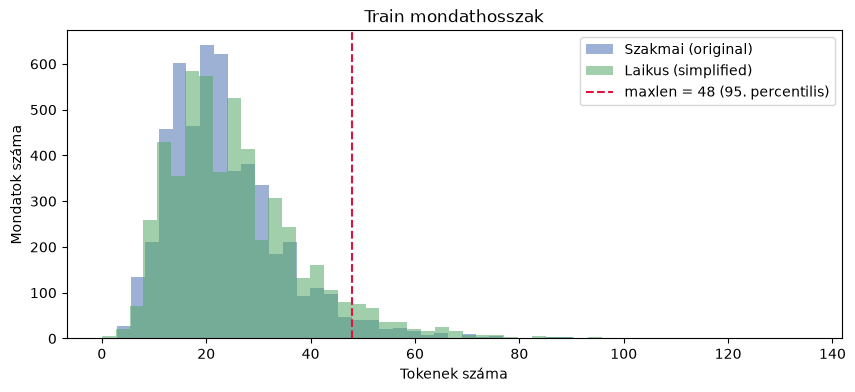

Levágott train mondatok: 4.7%


In [2]:
lengths = pd.Series([len(s) for s in data.tokenizer.texts_to_sequences(data.train_df.text)])
fig, ax = plt.subplots(figsize=(10, 4))
for label, name, color in [(1, "Szakmai (original)", "#4C72B0"), (0, "Laikus (simplified)", "#55A868")]:
    ax.hist(lengths[data.train_df.label.values == label], bins=50, alpha=0.55, label=name, color=color)
ax.axvline(data.maxlen, color="crimson", ls="--", label=f"maxlen = {data.maxlen} (95. percentilis)")
ax.set_xlabel("Tokenek száma"); ax.set_ylabel("Mondatok száma"); ax.legend(); ax.set_title("Train mondathosszak")
plt.show()
print(f"Levágott train mondatok: {(lengths > data.maxlen).mean():.1%}")

### Modell és segédfüggvények

In [3]:
def build_model(mask_zero=True, dropout=0.3, pool_dropout=0.0, dense_units=64):
    model = keras.Sequential([
        keras.Input(shape=(data.maxlen,)),
        layers.Embedding(data.vocab_size, dp.EMBED_DIM, mask_zero=mask_zero),
        layers.GlobalAveragePooling1D(),
        *([layers.Dropout(pool_dropout)] if pool_dropout else []),
        layers.Dense(dense_units, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ], name="baseline_gap")
    return dp.compile_model(model)


def run_config(label, seeds=SEEDS, **params):
    """Egy beállítás tanítása több seeddel; a validációs metrikák átlaga és szórása."""
    rows, histories = [], {}
    for seed in seeds:
        dp.set_seeds(seed)
        model = build_model(**params)
        history, seconds = dp.fit(model, data)
        r = dp.evaluate(model, data, split="val")
        rows.append({"val_acc": r["accuracy"], "val_f1": r["f1"],
                     "val_loss": min(history.history["val_loss"]),
                     "best_epoch": dp.best_epoch(history), "sec": seconds})
        histories[seed] = history
    df = pd.DataFrame(rows)
    summary = {"beállítás": label, **params,
               "val_acc": df.val_acc.mean(), "±acc": df.val_acc.std(),
               "val_f1": df.val_f1.mean(), "val_loss": df.val_loss.mean(),
               "legjobb epoch": df.best_epoch.mean(), "idő (s)": df.sec.mean()}
    return summary, histories[seeds[0]]


fmt = {"val_acc": "{:.4f}", "±acc": "{:.4f}", "val_f1": "{:.4f}", "val_loss": "{:.4f}",
       "legjobb epoch": "{:.1f}", "idő (s)": "{:.1f}"}
dp.set_seeds(); build_model().summary()

E0000 00:00:1794300342.204796   10214 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "baseline_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 48, 100)        │     1,189,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 100)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,195,929 (4.56 MB)

 Trainable params: 1,195,929 (4.56 MB)

 Non-trainable params: 0 (0.00 B)

## 1. kísérlet: `mask_zero` ki és be

beállítás,mask_zero,dropout,val_acc,±acc,val_f1,val_loss,legjobb epoch,idő (s)
mask_zero=False,False,0.300000,0.7596,0.0294,0.7312,0.4789,1.7,6.2
mask_zero=True,True,0.300000,0.8041,0.0122,0.7931,0.4327,2.0,6.8


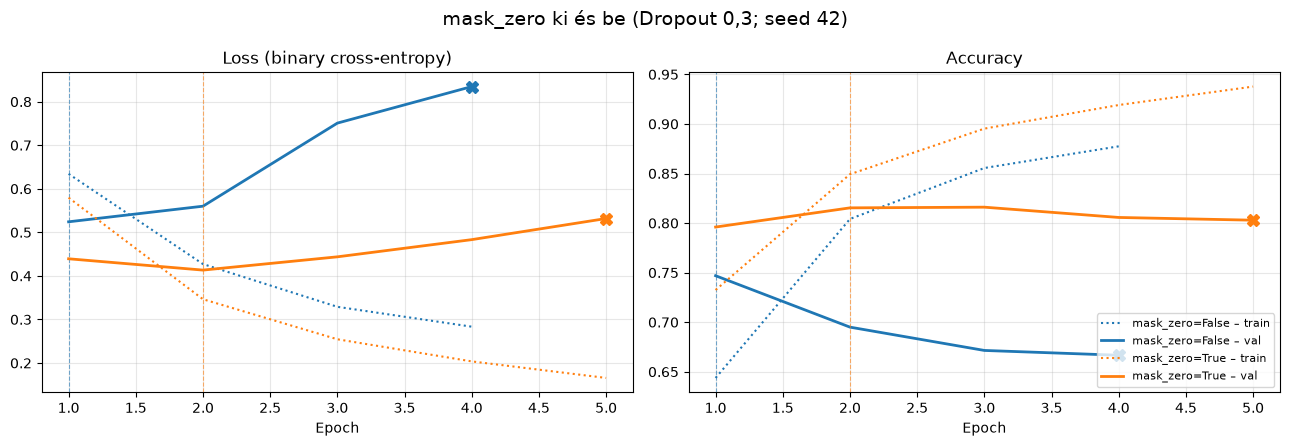

In [4]:
exp1, exp1_hist = [], {}
for mz in [False, True]:
    s, h = run_config(f"mask_zero={mz}", mask_zero=mz, dropout=0.3)
    exp1.append(s); exp1_hist[f"mask_zero={mz}"] = h
exp1 = pd.DataFrame(exp1)
display(exp1.style.format(fmt).hide(axis="index"))
dp.plot_history(exp1_hist, "mask_zero ki és be (Dropout 0,3; seed 42)"); plt.show()

**Eredmény:** a `mask_zero=True` átlagosan **~4,5 százalékponttal** jobb val accuracyt ad (0,804 vs 0,760), és a szórása is kisebb. Maszk nélkül a mondatvektor `(Σ valódi szavak + Σ padding) / maxlen`. Egy rövid mondatnál ez nagyrészt a padding-token embeddingje, így a mondathossz „belekeveredik” a reprezentációba, és a valódi szavak súlya felhígul. A maszkkal csak a valódi tokeneket átlagolja.

## 2. kísérlet: Dropout-arány
A maszkot az 1. kísérlet alapján választjuk (a magasabb átlagos val_acc nyer).

In [5]:
best_mask = bool(exp1.sort_values("val_acc", ascending=False).iloc[0]["mask_zero"])
print("Választott mask_zero:", best_mask)

exp2, exp2_hist = [], {}
for drop in [0.0, 0.2, 0.3, 0.5]:
    s, h = run_config(f"Dropout {drop}", mask_zero=best_mask, dropout=drop)
    exp2.append(s); exp2_hist[f"Dropout {drop}"] = h
s, h = run_config("Dropout 0.3 + pooling után 0.3", mask_zero=best_mask, dropout=0.3, pool_dropout=0.3)
exp2.append(s); exp2_hist["Dropout 0.3 + 0.3"] = h
exp2 = pd.DataFrame(exp2)
display(exp2.style.format(fmt).hide(axis="index"))

Választott mask_zero: True


beállítás,mask_zero,dropout,val_acc,±acc,val_f1,val_loss,legjobb epoch,idő (s),pool_dropout
Dropout 0.0,True,0.000000,0.7997,0.0182,0.7889,0.4347,1.7,6.5,nan
Dropout 0.2,True,0.200000,0.8029,0.0135,0.7917,0.4345,2.0,6.8,nan
Dropout 0.3,True,0.300000,0.8041,0.0122,0.7931,0.4327,2.0,7.2,nan
Dropout 0.5,True,0.500000,0.8018,0.0137,0.7911,0.4324,2.0,6.9,nan
Dropout 0.3 + pooling után 0.3,True,0.300000,0.7969,0.0167,0.7839,0.4392,2.0,7.0,0.300000


## 3. Tanulási görbe Dropout nélkül és Dropouttal
Itt **nincs** EarlyStopping, mind a 30 epoch lefut, így látszik, hol fordul felfelé a validációs loss. A szaggatott vonal a legjobb val_loss epochja (ezt tartja meg a `restore_best_weights=True`), az × pedig az, ahol a `patience=3` mellett az EarlyStopping megállt volna.

Dropout nélkül   legjobb val_loss: 0.4132 (epoch 2), 30. epoch val_loss: 1.2547, train acc: 0.9790


Dropout 0,5      legjobb val_loss: 0.4135 (epoch 2), 30. epoch val_loss: 1.5772, train acc: 0.9790


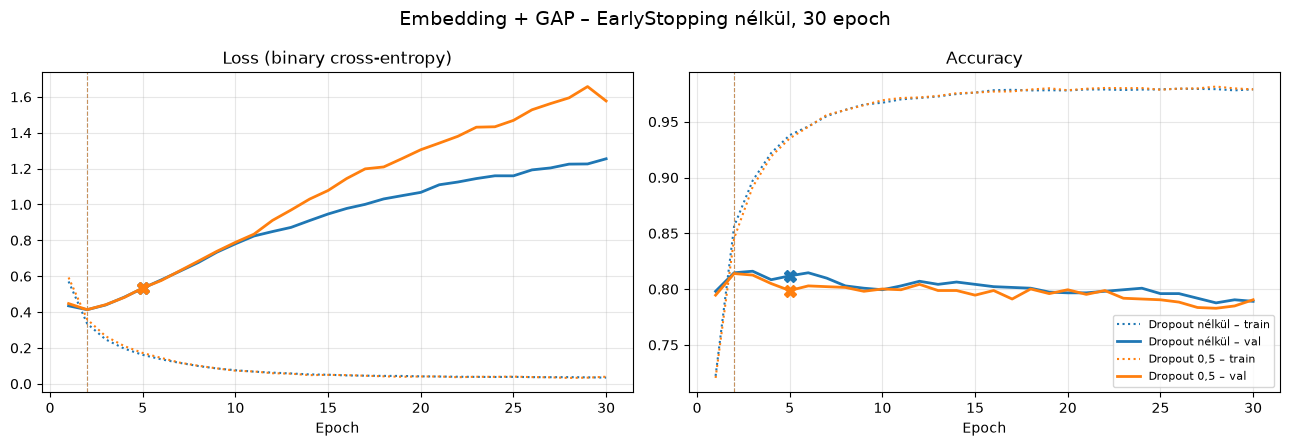

In [6]:
curves = {}
for label, drop in [("Dropout nélkül", 0.0), ("Dropout 0,5", 0.5)]:
    dp.set_seeds(42)
    model = build_model(mask_zero=best_mask, dropout=drop)
    history, _ = dp.fit(model, data, epochs=30, use_early_stopping=False)
    curves[label] = history
    h = history.history
    print(f"{label:16s} legjobb val_loss: {min(h['val_loss']):.4f} (epoch {dp.best_epoch(history)}),"
          f" 30. epoch val_loss: {h['val_loss'][-1]:.4f}, train acc: {h['accuracy'][-1]:.4f}")
dp.plot_history(curves, "Embedding + GAP – EarlyStopping nélkül, 30 epoch"); plt.show()

**Megfigyelés:** a legjobb val_loss mindkét esetben a **2. epochnál** van (~0,41). Utána a train loss tovább csökken (train accuracy ~98%), a val_loss viszont 30 epoch alatt 1,2–1,6-ra nő, a val accuracy pedig ~81%-ról ~79%-ra esik vissza. Ez klasszikus túltanulás.

A ~1,2 millió paraméter 99,5%-a az Embedding rétegben van (11 894 szó × 100 dimenzió), ezért a Dense utáni Dropout itt alig segít: a túltanulás az embeddingben történik. A 2. kísérletben a Dropout-arányok közti különbség (0,80–0,804) kisebb a seedek közti szórásnál (±0,012–0,018). Ennél a modellnél ezért az **EarlyStopping a fő védekezés**: a 2. epoch után még 3 epochig vár (×), megáll, és a `restore_best_weights=True` miatt a 2. epoch súlyait tartja meg.

## Végső modell és kiértékelés a teszthalmazon
A beállítást a validációs eredmények alapján választjuk (legmagasabb átlagos val_acc). A teszthalmazt csak ez az egy modell látja, ez kerül a közös táblába (`results/baseline.json`).

In [7]:
all_exp = pd.concat([exp1.assign(kísérlet=1), exp2.assign(kísérlet=2)], ignore_index=True)
best = all_exp.sort_values("val_acc", ascending=False).iloc[0]
final_params = {"mask_zero": bool(best["mask_zero"]), "dropout": float(best["dropout"]),
                "pool_dropout": float(best["pool_dropout"]) if pd.notna(best.get("pool_dropout")) else 0.0}
print("Választott beállítás:", best["beállítás"], final_params)

dp.set_seeds(42)
final_model = build_model(**final_params)
final_history, final_seconds = dp.fit(final_model, data)
test_result = dp.evaluate(final_model, data, split="test")
print(f"Teszt accuracy: {test_result['accuracy']:.4f}   F1: {test_result['f1']:.4f}   "
      f"epochok: {len(final_history.history['loss'])} (legjobb: {dp.best_epoch(final_history)})   idő: {final_seconds:.1f} s")

Választott beállítás: mask_zero=True {'mask_zero': True, 'dropout': 0.3, 'pool_dropout': 0.0}


Teszt accuracy: 0.8071   F1: 0.8044   epochok: 5 (legjobb: 2)   idő: 6.9 s


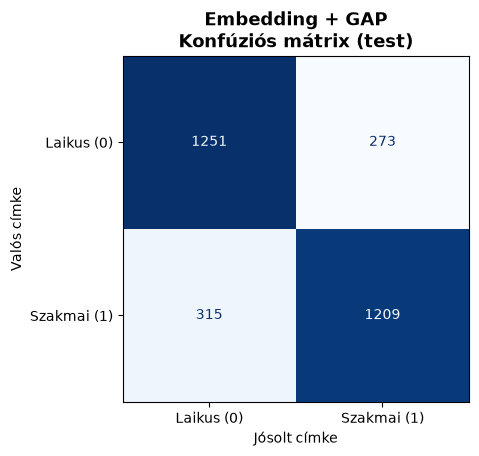

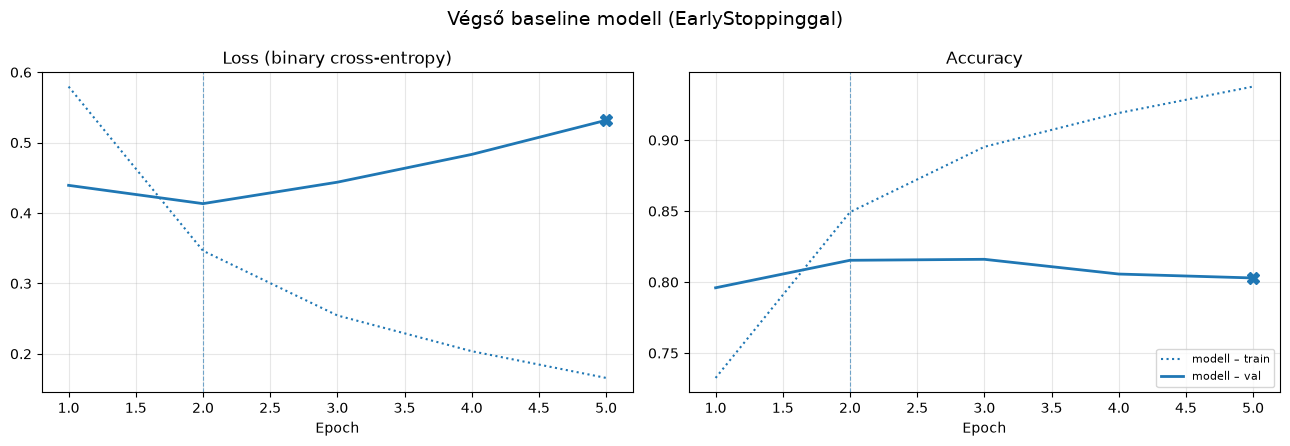

In [8]:
fig, ax = plt.subplots(figsize=(5, 4.5))
dp.plot_confusion(test_result["confusion_matrix"], "Embedding + GAP\nKonfúziós mátrix (test)", ax=ax); plt.show()
dp.plot_history(final_history, "Végső baseline modell (EarlyStoppinggal)"); plt.show()

### Seed-érzékenység
Tájékoztató adat, a választásban nem vett részt: ugyanez a beállítás a három seeddel a teszthalmazon. Így látszik, mekkora eltérés számít zajnak az összehasonlításban.

In [9]:
seed_scores = []
for seed in SEEDS:
    dp.set_seeds(seed)
    m = build_model(**final_params)
    dp.fit(m, data)
    r = dp.evaluate(m, data, split="test")
    seed_scores.append((seed, r["accuracy"], r["f1"]))
seed_df = pd.DataFrame(seed_scores, columns=["seed", "test_acc", "test_f1"])
display(seed_df.round(4))
print(f"Átlag: acc {seed_df.test_acc.mean():.4f} ± {seed_df.test_acc.std():.4f},  F1 {seed_df.test_f1.mean():.4f} ± {seed_df.test_f1.std():.4f}")

,seed,test_acc,test_f1
0,42,0.8071,0.8044
1,43,0.7946,0.7802
2,44,0.7874,0.7687


Átlag: acc 0.7964 ± 0.0100,  F1 0.7844 ± 0.0182


In [10]:
path = dp.save_result(
    key="baseline", name="Embedding + GAP (baseline)", model=final_model,
    history=final_history, result=test_result, train_seconds=final_seconds, data=data,
    params={**final_params, "dense_units": 64},
    notes=f"3 seed teszt átlag: acc {seed_df.test_acc.mean():.4f} ± {seed_df.test_acc.std():.4f}",
)
print("Mentve:", path)

Mentve: /home/fap/suli/ProjektmunkaI/results/baseline.json
